# MLSM Lab 1 — Interactive Training

The notebook handles interaction and presentation. The logic is in `run_lab1.py`, and model definitions are in `model_definitions.py`. Run the cells in order.

In [9]:
from pathlib import Path
import importlib
import run_lab1

# Reload the module so the notebook uses the latest saved code.
importlib.reload(run_lab1)
print(f"Using run_lab1.py from: {Path(run_lab1.__file__).resolve()}")

from run_lab1 import (
    load_dataset, select_models, evaluate_models,
    get_confusion_data, create_cv, display_results, plot_confusion_matrix,
    save_run_outputs,
)


Using run_lab1.py from: /home/lucialinux/MLSM-labs/Lab1/run_lab1.py


## 1. Select the Dataset and Load the Data

In [10]:
print("1 -> GenreAll | 2 -> features-30-sec | 3 -> features-3-sec")
dataset_choice = input("Dataset [1/2/3]: ").strip()
dataset_name, filename, X, y, class_counts = load_dataset(dataset_choice)
print(f"{dataset_name}: {len(y)} samples, {X.shape[1]} features")
display_results(class_counts.to_frame())

1 -> GenreAll | 2 -> features-30-sec | 3 -> features-3-sec
features-30-sec: 1000 samples, 58 features


,Samples
label,
blues,100
classical,100
country,100
disco,100
hiphop,100
jazz,100
metal,100
pop,100
reggae,100


## 2. Select a Model

In [11]:
print("l -> Logistic Regression | k -> k-NN | d -> Decision Tree | a -> ANN | all -> All models")
model_choice = input("Model [l/k/d/a/all]: ").strip()
selected_models = select_models(dataset_name, X.shape[1], model_choice)
print("Models:", ", ".join(selected_models))

l -> Logistic Regression | k -> k-NN | d -> Decision Tree | a -> ANN | all -> All models
Models: Logistic Regression, k-NN, Decision Tree, Artificial Neural Network


## 3. Train and Evaluate

Stratified 10-fold cross-validation is used. This cell may take several minutes.

In [12]:
cv = create_cv()
results_df = evaluate_models(X, y, selected_models, cv)
print(f"Configurations evaluated: {len(results_df)}")

Configurations evaluated: 87


## 4. Results

In [13]:
display_results(results_df)

,Algorithm,Parameters,Train accuracy,CV accuracy,Overfitting gap
0,Artificial Neural Network,"{'model__alpha': 0.001, 'model__hidden_layer_sizes': (128, 64), 'model__learning_rate_init': 0.001, 'selector__k': 'all'}",0.9991,0.7620,0.2371
1,Artificial Neural Network,"{'model__alpha': 0.0001, 'model__hidden_layer_sizes': (128, 64), 'model__learning_rate_init': 0.001, 'selector__k': 'all'}",0.9991,0.7600,0.2391
2,Artificial Neural Network,"{'model__alpha': 0.0001, 'model__hidden_layer_sizes': (100, 50), 'model__learning_rate_init': 0.001, 'selector__k': 'all'}",0.9991,0.7560,0.2431
3,Artificial Neural Network,"{'model__alpha': 0.001, 'model__hidden_layer_sizes': (100, 50), 'model__learning_rate_init': 0.001, 'selector__k': 'all'}",0.9991,0.7560,0.2431
4,Artificial Neural Network,"{'model__alpha': 0.001, 'model__hidden_layer_sizes': (128, 64), 'model__learning_rate_init': 0.001, 'selector__k': 30}",0.9991,0.7390,0.2601
5,Artificial Neural Network,"{'model__alpha': 0.0001, 'model__hidden_layer_sizes': (100, 50), 'model__learning_rate_init': 0.001, 'selector__k': 40}",0.9991,0.7380,0.2611
6,Logistic Regression,"{'model__C': 1.0, 'selector__k': 'all'}",0.8856,0.7370,0.1486
7,Artificial Neural Network,"{'model__alpha': 0.0001, 'model__hidden_layer_sizes': (128, 64), 'model__learning_rate_init': 0.001, 'selector__k': 30}",0.9991,0.7360,0.2631
8,Artificial Neural Network,"{'model__alpha': 0.001, 'model__hidden_layer_sizes': (100, 50), 'model__learning_rate_init': 0.001, 'selector__k': 40}",0.9991,0.7350,0.2641
9,Artificial Neural Network,"{'model__alpha': 0.001, 'model__hidden_layer_sizes': (128, 64), 'model__learning_rate_init': 0.001, 'selector__k': 40}",0.9991,0.7350,0.2641


## 5. Select a Row for the Confusion Matrix

The matrix uses *out-of-fold* predictions from cross-validation.

In [14]:
row_choice = input(f"Row index [0–{len(results_df)-1}] or q to skip: ").strip().lower()

## 6. Confusion Matrix

Artificial Neural Network | CV accuracy: 0.7620 | Overfitting gap: 0.2371
Parameters: {'model__alpha': 0.001, 'model__hidden_layer_sizes': (128, 64), 'model__learning_rate_init': 0.001, 'selector__k': 'all'}


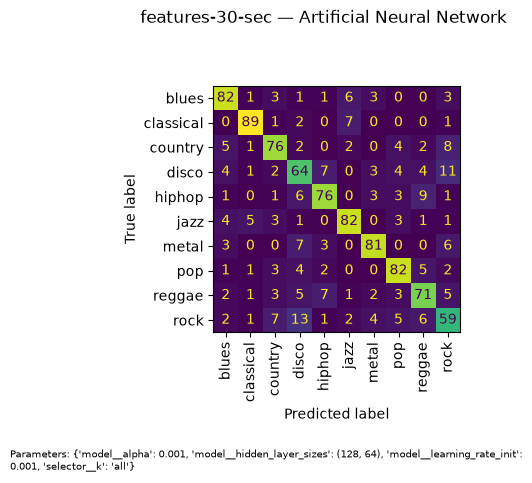

In [15]:
fig = None
if row_choice == "q":
    print("Confusion matrix skipped.")
else:
    row_index = int(row_choice)
    matrix, classes, row = get_confusion_data(X, y, selected_models, results_df, row_index, cv)
    print(f"{row['Algorithm']} | CV accuracy: {row['CV accuracy']:.4f} | Overfitting gap: {row['Overfitting gap']:.4f}\nParameters: {row['Parameters']}")
    title = f"{dataset_name} — {row['Algorithm']}"
    fig = plot_confusion_matrix(matrix, classes, title, row["Parameters"])

## 7. Save Results (Optional)

This cell is independent and can be run again after the analysis is complete. If you choose to save, an Excel file containing the results and configuration tables, along with the confusion matrix figure, will be created in `Lab1/results/`.

In [16]:
save_run_outputs(results_df, dataset_name, selected_models, fig)

Files will be saved in: /home/lucialinux/MLSM-labs/Lab1/results/features-30-sec
Excel file saved to: /home/lucialinux/MLSM-labs/Lab1/results/features-30-sec/30sec-all.xlsx
Figure saved to: /home/lucialinux/MLSM-labs/Lab1/results/features-30-sec/30sec-all.png
